# Figure 2 — Benchmarking cell-state transition predictions

Run **Restart Kernel and Run All Cells**. Every panel is redrawn from checked numerical tables; no saved manuscript image is used as an input. The cells export new PNG/PDF/SVG files and assemble the complete figure.

This notebook follows the numerical manuscript snapshot dated 2026-10-13. Dataset display names were aligned with the manuscript on 2026-10-14: **RHY 1–4** denote the four rhynchophylline-versus-saline mouse brain datasets. Table previews use display names; the underlying CSV identifiers and numerical values remain unchanged. [Plotting source](../reproduction/figure2.py) · [Data provenance](../reproduction/manifest.json) · [Reproduction guide](README.md). The original model implementation and frozen selection remain unchanged. Training seeds measure optimization variability, not biological replication.

In [1]:
from pathlib import Path
import os
import sys

# Works from the repository root or notebooks/; an explicit root is optional.
configured = os.environ.get("SPIKE_CODE_ROOT")
REPO_ROOT = Path(configured).expanduser().resolve() if configured else next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "reproduction/manifest.json").is_file()
)
sys.path.insert(0, str(REPO_ROOT))
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
import matplotlib.pyplot as plt
from IPython.display import display
from reproduction.common import audit, read, save, finish, OUTPUT, display_table
from reproduction import figure2 as drawing

manifest = audit()
figures = {}


Matplotlib is building the font cache; this may take a moment.


Input audit: PASS (33 numerical tables)
Figure protocol: Released manuscript graph predictions for all seven datasets; matched split-42 State, seeds 41/42/43. Original frozen model selection remains unchanged.


## A. Population gene means

Pearson r and RMSE. Points are seven dataset means over training seeds; bars and error bars show the across-dataset mean and sample SD. Dashed lines mark the minimum and maximum method means.

Numerical input: [`benchmark.csv`](../reproduction/tables/benchmark.csv).

Source table: benchmark.csv (35, 9)


,dataset,method,expression_r,expression_rmse,response_auc,pearson,Corr,w1,cosine_mean
0,RHY 1,spike,0.997916,0.037953,0.874479,0.903826,0.978610,0.011804,0.973379
1,RHY 1,scGPT,0.978447,0.217074,0.796100,0.682098,0.466394,0.195029,0.852767
2,RHY 1,scGen,0.978952,0.144315,0.823955,0.714533,0.615294,0.172322,0.850751
3,RHY 1,CellOT,0.677402,0.533615,0.277911,-0.607522,0.764755,0.045428,0.918669
4,RHY 2,spike,0.995481,0.041482,0.846786,0.918525,0.990412,0.005280,0.954825


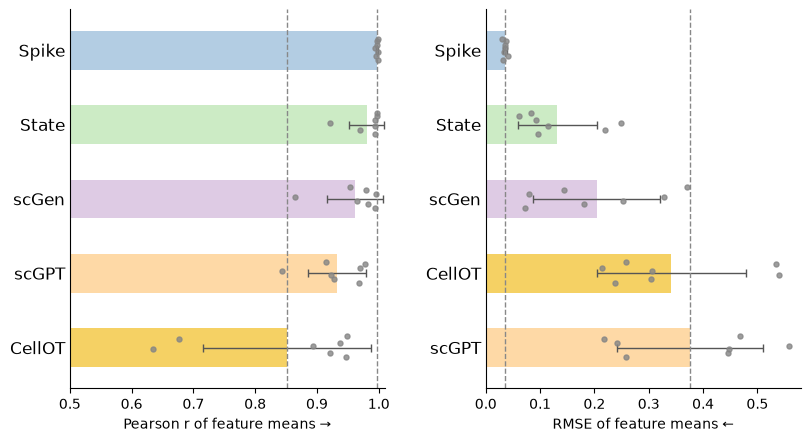

In [2]:
data_a = read('benchmark.csv')
print("Source table:", 'benchmark.csv', data_a.shape)
display(display_table(data_a.head(5)))
figures['a'] = drawing.panel_a()
save(figures['a'], 2, 'a')
display(figures['a'])
plt.close(figures['a'])

## B. Response, spatial and TF-support agreement

Response-direction AUC, Spatial Moran-profile r and population TF cosine. Small dots show dataset means, large dots show their mean ± SD; dashed guides show the Spike median.

Numerical input: [`benchmark.csv`](../reproduction/tables/benchmark.csv).

Source table: benchmark.csv (35, 9)


,dataset,method,expression_r,expression_rmse,response_auc,pearson,Corr,w1,cosine_mean
0,RHY 1,spike,0.997916,0.037953,0.874479,0.903826,0.978610,0.011804,0.973379
1,RHY 1,scGPT,0.978447,0.217074,0.796100,0.682098,0.466394,0.195029,0.852767
2,RHY 1,scGen,0.978952,0.144315,0.823955,0.714533,0.615294,0.172322,0.850751
3,RHY 1,CellOT,0.677402,0.533615,0.277911,-0.607522,0.764755,0.045428,0.918669
4,RHY 2,spike,0.995481,0.041482,0.846786,0.918525,0.990412,0.005280,0.954825


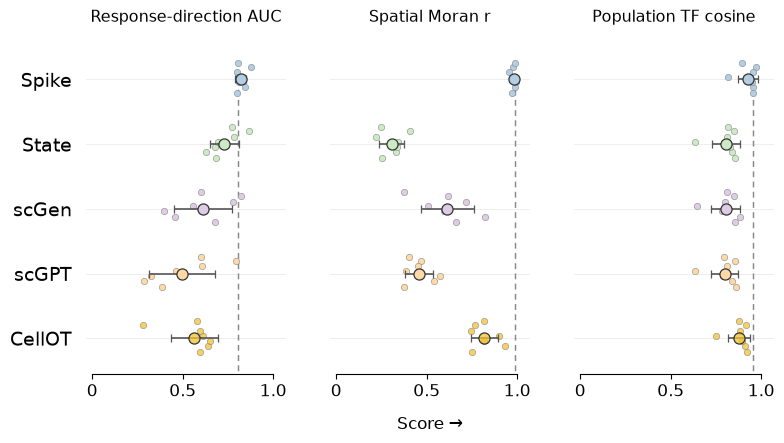

In [3]:
data_b = read('benchmark.csv')
print("Source table:", 'benchmark.csv', data_b.shape)
display(display_table(data_b.head(5)))
figures['b'] = drawing.panel_b()
save(figures['b'], 2, 'b')
display(figures['b'])
plt.close(figures['b'])

## C. Spatial Ttr expression

RHY 3: observed source expression and predictions at the same source spots. All six methods share coordinates and a pooled 99th-percentile color maximum. Spike is the released graph prediction; State is the matched split-42 three-seed mean.

Numerical input: [`benchmark_spatial.csv`](../reproduction/tables/benchmark_spatial.csv).

Source table: benchmark_spatial.csv (3030, 7)


,index,x,y,expression,dataset,gene,method
0,AAATCGTGTACCACAA-1-c,2027,2549,0.000000,RHY 3,Ttr,Source
1,AAATGGTCAATGTGCC-1-c,1887,2017,1.717089,RHY 3,Ttr,Source
2,AACAGGTAGTATGGAT-1-c,3611,2788,0.000000,RHY 3,Ttr,Source
3,AACATATCAACTGGTG-1-c,3220,1725,8.595134,RHY 3,Ttr,Source
4,AACCCTACTGTCAATA-1-c,3138,2354,0.000000,RHY 3,Ttr,Source


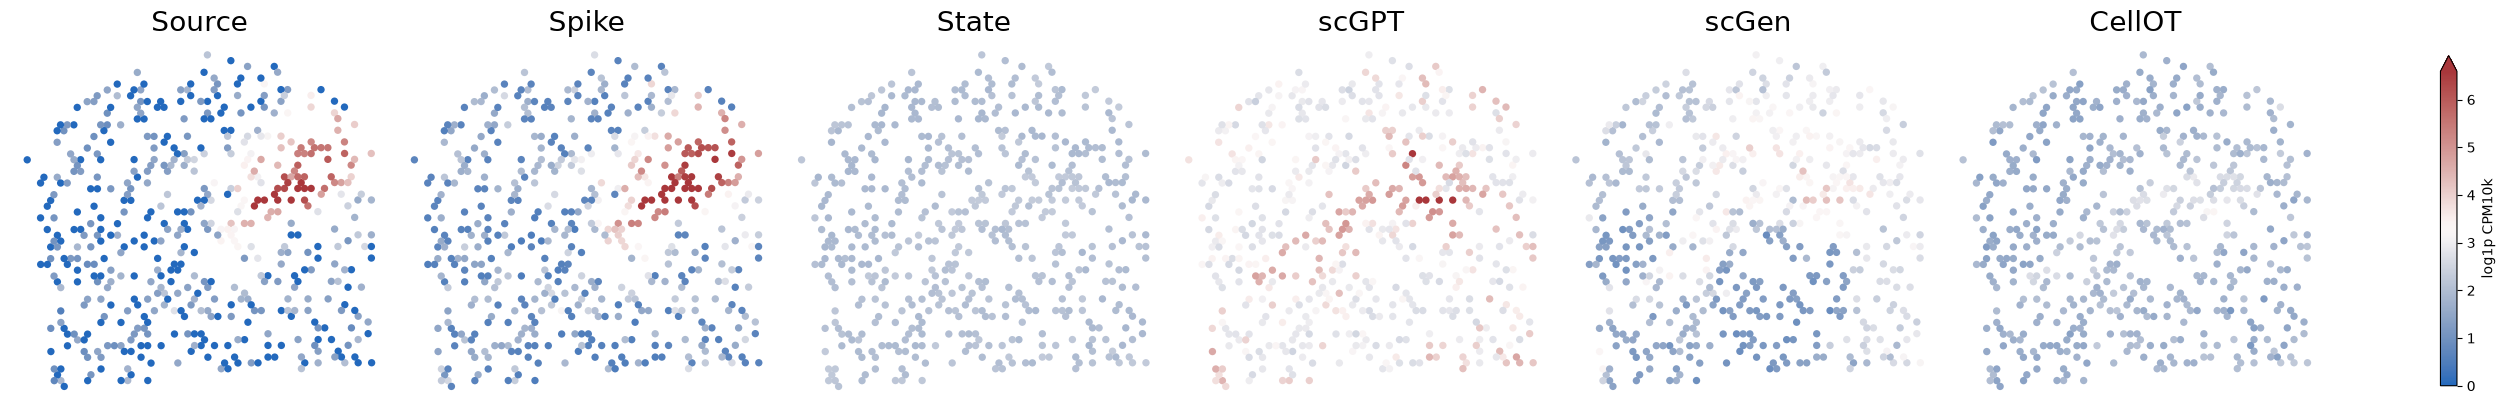

In [4]:
data_c = read('benchmark_spatial.csv')
print("Source table:", 'benchmark_spatial.csv', data_c.shape)
display(display_table(data_c.head(5)))
figures['c'] = drawing.panel_c()
save(figures['c'], 2, 'c')
display(figures['c'])
plt.close(figures['c'])

## D. Positive-expression distributions

RHY 1: Sgk1 and Ttr. Reflected Gaussian KDE uses positive values, 1.5 × Scott bandwidth and per-curve peak normalization. Source and target populations are unpaired. Zero-expression observations remain in the source table.

Numerical input: [`benchmark_distributions.csv`](../reproduction/tables/benchmark_distributions.csv).

Source table: benchmark_distributions.csv (6120, 7)


,Expression,Source,Dataset,Gene,Seed,Cell,split_seed
0,0.000000,Control,RHY 1,Sgk1,observed,AAAGTAGCATTGCTCA-1-c,NaN
1,2.001549,Control,RHY 1,Sgk1,observed,AAATAGGGTGCTATTG-1-c,NaN
2,2.496675,Control,RHY 1,Sgk1,observed,AAATGGCATGTCTTGT-1-c,NaN
3,2.129113,Control,RHY 1,Sgk1,observed,AAATGGTCAATGTGCC-1-c,NaN
4,1.434597,Control,RHY 1,Sgk1,observed,AAATTTGCGGGTGTGG-1-c,NaN


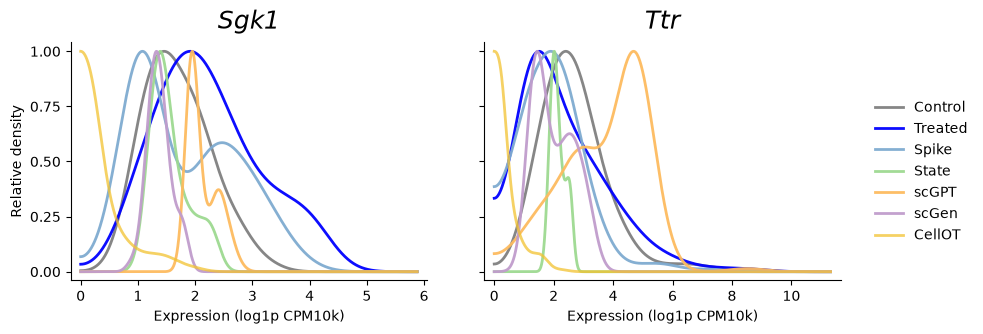

In [5]:
data_d = read('benchmark_distributions.csv')
print("Source table:", 'benchmark_distributions.csv', data_d.shape)
display(display_table(data_d.head(5)))
figures['d'] = drawing.panel_d()
save(figures['d'], 2, 'd')
display(figures['d'])
plt.close(figures['d'])

## E. Receptor–TF support Wasserstein distance

One column per method and one bar per dataset; all columns use the same 0–0.30 axis. Values are the released equal-receptor mean marginal W1 distances.

Numerical input: [`benchmark.csv`](../reproduction/tables/benchmark.csv).

Source table: benchmark.csv (35, 9)


,dataset,method,expression_r,expression_rmse,response_auc,pearson,Corr,w1,cosine_mean
0,RHY 1,spike,0.997916,0.037953,0.874479,0.903826,0.978610,0.011804,0.973379
1,RHY 1,scGPT,0.978447,0.217074,0.796100,0.682098,0.466394,0.195029,0.852767
2,RHY 1,scGen,0.978952,0.144315,0.823955,0.714533,0.615294,0.172322,0.850751
3,RHY 1,CellOT,0.677402,0.533615,0.277911,-0.607522,0.764755,0.045428,0.918669
4,RHY 2,spike,0.995481,0.041482,0.846786,0.918525,0.990412,0.005280,0.954825


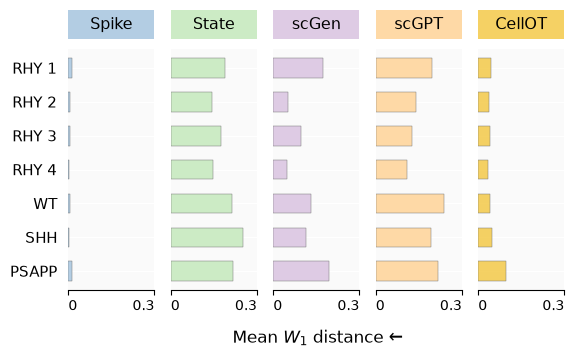

In [6]:
data_e = read('benchmark.csv')
print("Source table:", 'benchmark.csv', data_e.shape)
display(display_table(data_e.head(5)))
figures['e'] = drawing.panel_e()
save(figures['e'], 2, 'e')
display(figures['e'])
plt.close(figures['e'])

## Complete figure and output verification

The composite uses only the figures generated above, assembled in memory. It writes `complete.png`, `complete.pdf`, `complete.svg` and a validation record.

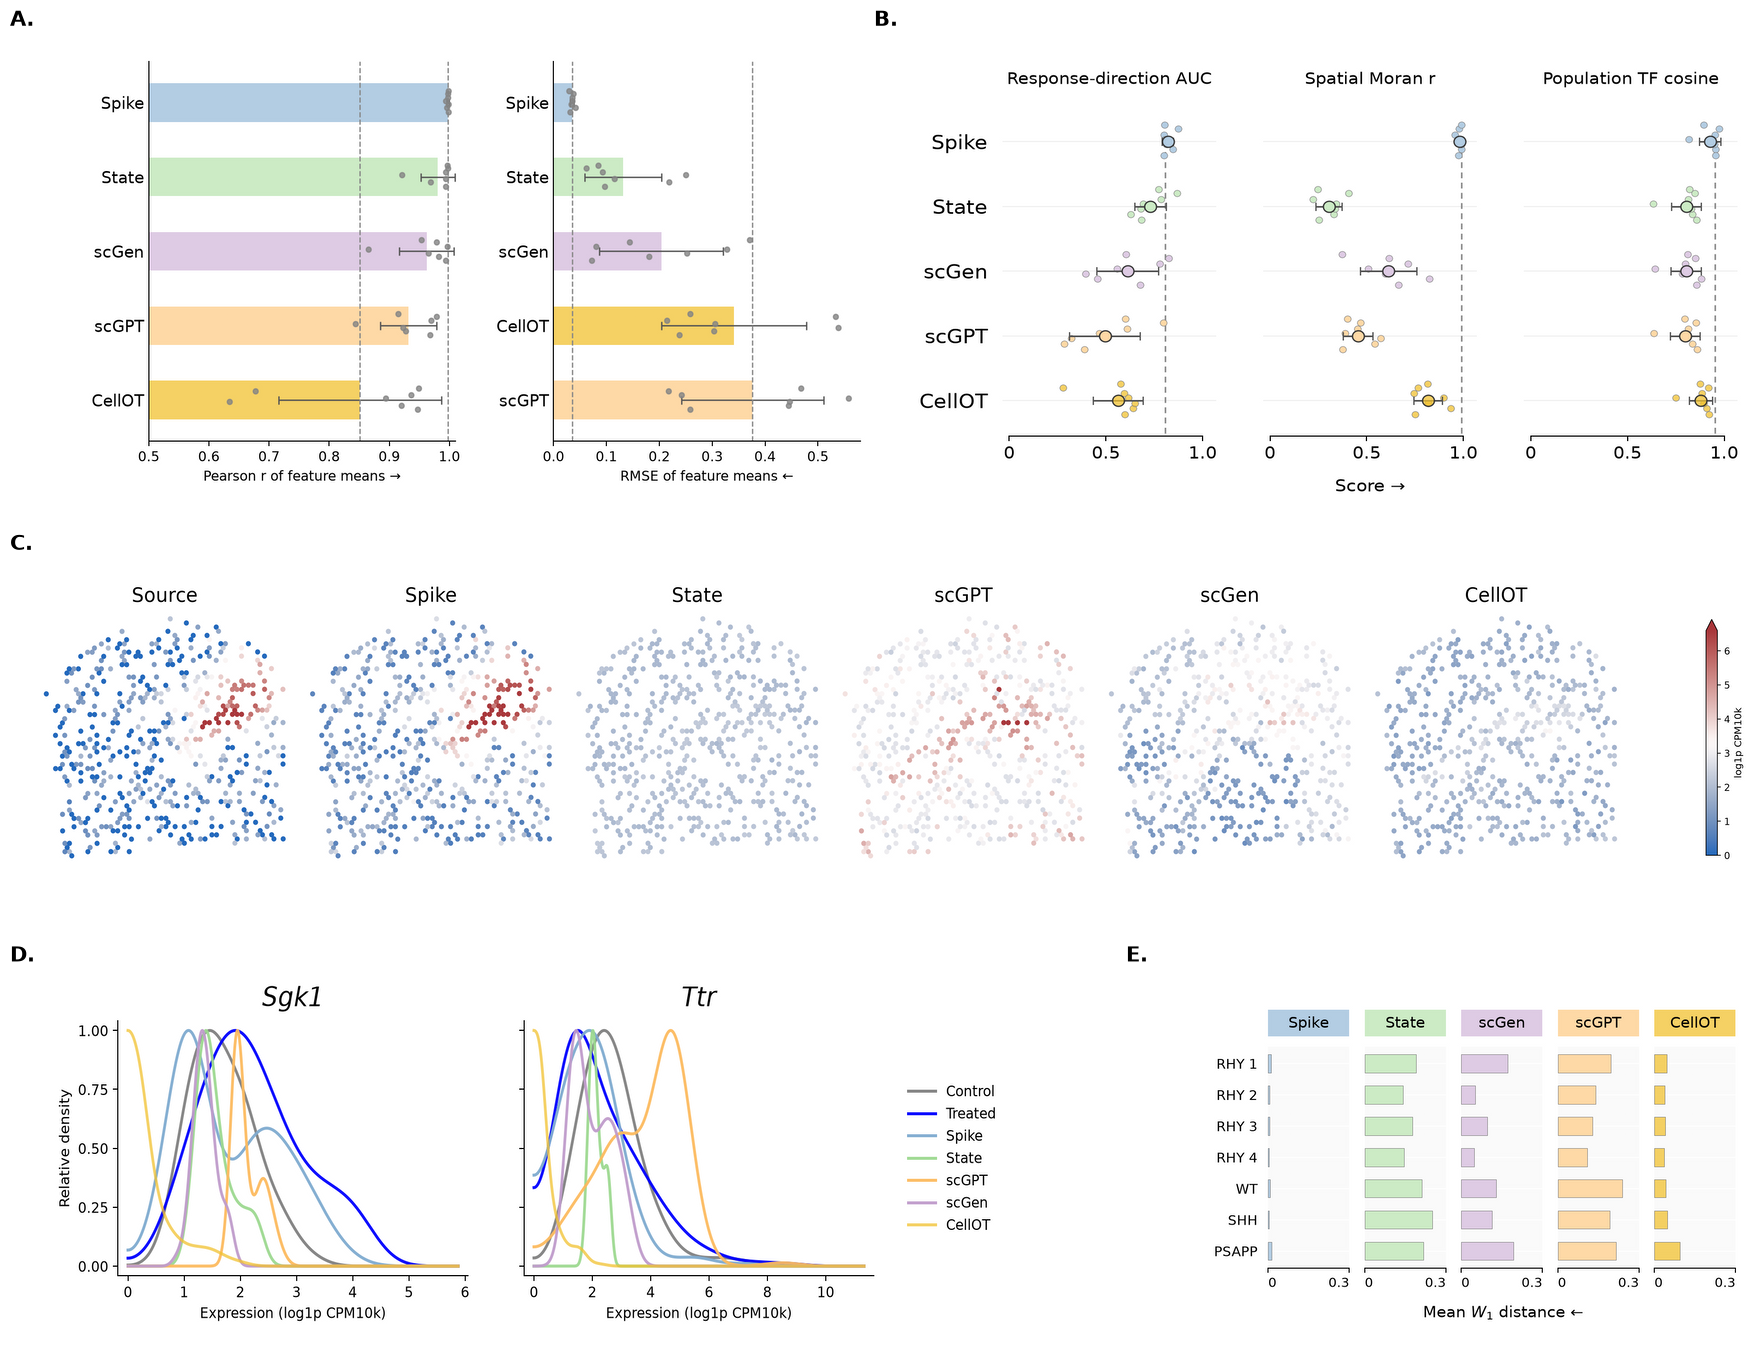

Figure 2: PASS — 5 panels redrawn from numerical tables
Outputs: /Users/jasmine/Documents/GitHub/spike/outputs/reproduction/figure2


In [7]:
complete = drawing.complete(figures)
save(complete, 2, "complete")
display(complete)
plt.close(complete)
report = finish(2, drawing.PANELS)